# **CVC-ClinicDB Dataset**

In [2]:
import torch
from segmentation_models import *

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("CUDA device found.")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("MPS device found.")
else:
    device = torch.device("cpu")
    print("Using CPU.")

CUDA device found.


In [3]:
# Dataset Paths
dataset_path = "data/CVC-ClinicDB"
image_dir = "Original"
mask_dir = "Ground Truth"

# Image Preprocessing Parameters
IMG_SIZE = (256, 256)  # Changed to (256, 256) as per the context

dataset = MedicalImageSegmentationData(
    dataset_path=dataset_path,
    image_dir=image_dir,
    mask_dir=mask_dir,
    img_size=IMG_SIZE,
    batch_size=8,
    test_size=0.1,
    random_state=42,
    binarize_mask=True,
)

train_loader, test_loader = dataset.dataloaders()

print(f"Total number of samples: {len(dataset)}")
print(f"Number of training samples: {len(train_loader.dataset)}")
print(f"Number of testing samples: {len(test_loader.dataset)}")

# dataset.visualize_samples()

Total number of samples: 612
Number of training samples: 550
Number of testing samples: 62


# Unet CVC model training config

In [4]:
cfg = TrainConfig(
    # --- General ---
    model_name = "ResUNet",
    dataset_name = "CVC-ClinicDB",
    criterion = "BCEDiceLoss",
    optimizer = "AdamW",
    epochs = 100,
    lr = 1e-3,
    weight_decay = 1e-4,

    # --- Scheduler ---
    scheduler = "ReduceLROnPlateau",
    scheduler_factor = 0.5,          # for ReduceLROnPlateau
    scheduler_patience = 5,            # for ReduceLROnPlateau
    mode = "min",

    # --- Training control ---
    early_stopping_patience = 10,

    # --- Paths / logging ---
    base_dir="model_comparisons",
    models_dir = "trained_models",
    history_dir = "models_history",
    loss_dir = "loss_plots",
    visualize_dir = "visualizations",
    logs_dir = "logs",
    use_wandb = True,
    wandb_project = "segmentation_models",
    wandb_run_name = None,
    wandb_watch_log_freq = 100,

    # --- Metrics ---
    threshold = 0.5,
    log_train_metrics = True
)

In [5]:
if cfg.use_wandb:
    from dotenv import load_dotenv
    load_dotenv()
    import wandb
    wandb.login(key=os.getenv("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /home/humblebee/.netrc
wandb: Currently logged in as: mironshoh (iv-drip-counter) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [6]:
model = resunet_small(in_channels=3, num_classes=1)
trainer = SegmentationTrainer(model, device, train_loader, test_loader, test_loader, cfg=cfg)
result = trainer.train()
result


2025-09-07 18:07:59 | INFO | ResUNet_model_CVC_ClinicDB_20250907_180759 | Logging to model_comparisons/logs/ResUNet_model_CVC_ClinicDB_20250907_180759.log
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


2025-09-07 18:08:00 | INFO | ResUNet_model_CVC_ClinicDB_20250907_180759 | W&B URL: https://wandb.ai/iv-drip-counter/segmentation_models/runs/4ick2bjl
100%|██████████| 8/8 [00:00<00:00, 12.21it/s]
2025-09-07 18:08:13 | INFO | ResUNet_model_CVC_ClinicDB_20250907_180759 | Epoch 001/100 | Train: 1.063149 | Val: 1.354057 | LR: 0.001000 | 13.16s | Val Dice: 0.0833 IoU: 0.0475 F1: 0.1002
2025-09-07 18:08:13 | INFO | ResUNet_model_CVC_ClinicDB_20250907_180759 | Saved best: model_comparisons/models/best_ResUNet_model_CVC_ClinicDB_20250907_180759.pth (val=1.354057)
100%|██████████| 8/8 [00:00<00:00,  8.36it/s]
2025-09-07 18:08:26 | INFO | ResUNet_model_CVC_ClinicDB_20250907_180759 | Epoch 002/100 | Train: 0.915248 | Val: 1.005139 | LR: 0.001000 | 12.68s | Val Dice: 0.2645 IoU: 0.1810 F1: 0.3585
2025-09-07 18:08:27 | INFO | ResUNet_model_CVC_ClinicDB_20250907_180759 | Saved best: model_comparisons/models/best_ResUNet_model_CVC_ClinicDB_20250907_180759.pth (val=1.005139)
100%|██████████| 8/8 [00:0

avg_flops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_fps,█▅▃▁▄▆▃▁▄▅▅▄▄▄▅▄▄▄▄▄▃▄▃▄▃▄▃▃▄▃▃▄▃▃▃▄▄▂
avg_gflops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_inference_time,▁▄▅█▄▃▆█▅▄▄▅▅▄▄▅▅▅▅▅▅▅▆▄▆▅▅▆▅▆▆▅▆▆▆▅▅▆
epoch_seconds,▃▂▂█▃▂▃▂▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▂▁▂▁▁▁▂▂▂▂▂▂▂▂▂
lr,█████████████████████████▃▃▃▃▃▃▃▃▁▁▁▁▁
num_trainable,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/dice,▁▂▂▃▃▃▃▃▄▄▄▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇▇███████████
train/f1,▁▂▂▃▃▃▃▃▄▄▄▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇▇███████████
train/iou,▁▂▂▂▂▂▃▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▇▆▇▇▇▇▇█████████
+11,...


{'best_val_loss': 0.35488382168114185,
 'epochs_ran': 38,
 'best_model_path': 'model_comparisons/models/best_ResUNet_model_CVC_ClinicDB_20250907_180759.pth',
 'loss_csv_path': 'model_comparisons/history/loss_history_ResUNet_CVC_ClinicDB_20250907_180759.csv',
 'wandb_url': 'https://wandb.ai/iv-drip-counter/segmentation_models/runs/4ick2bjl',
 'log_path': 'model_comparisons/logs/ResUNet_model_CVC_ClinicDB_20250907_180759.log'}

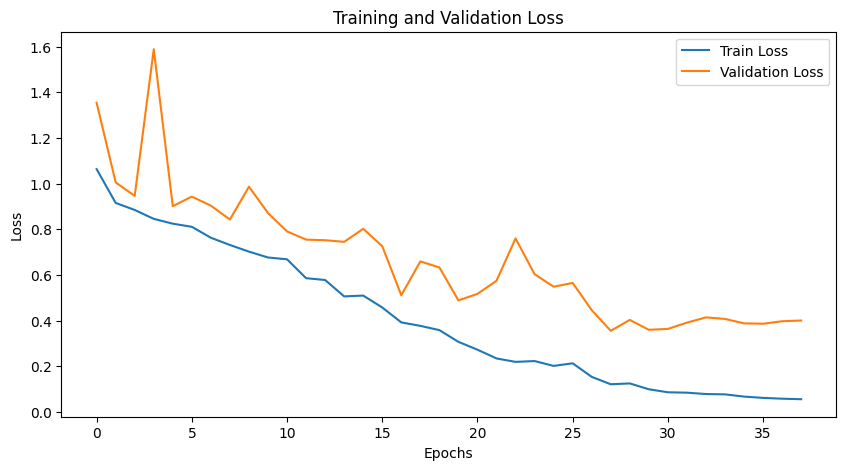

In [7]:
trainer.plot_losses()

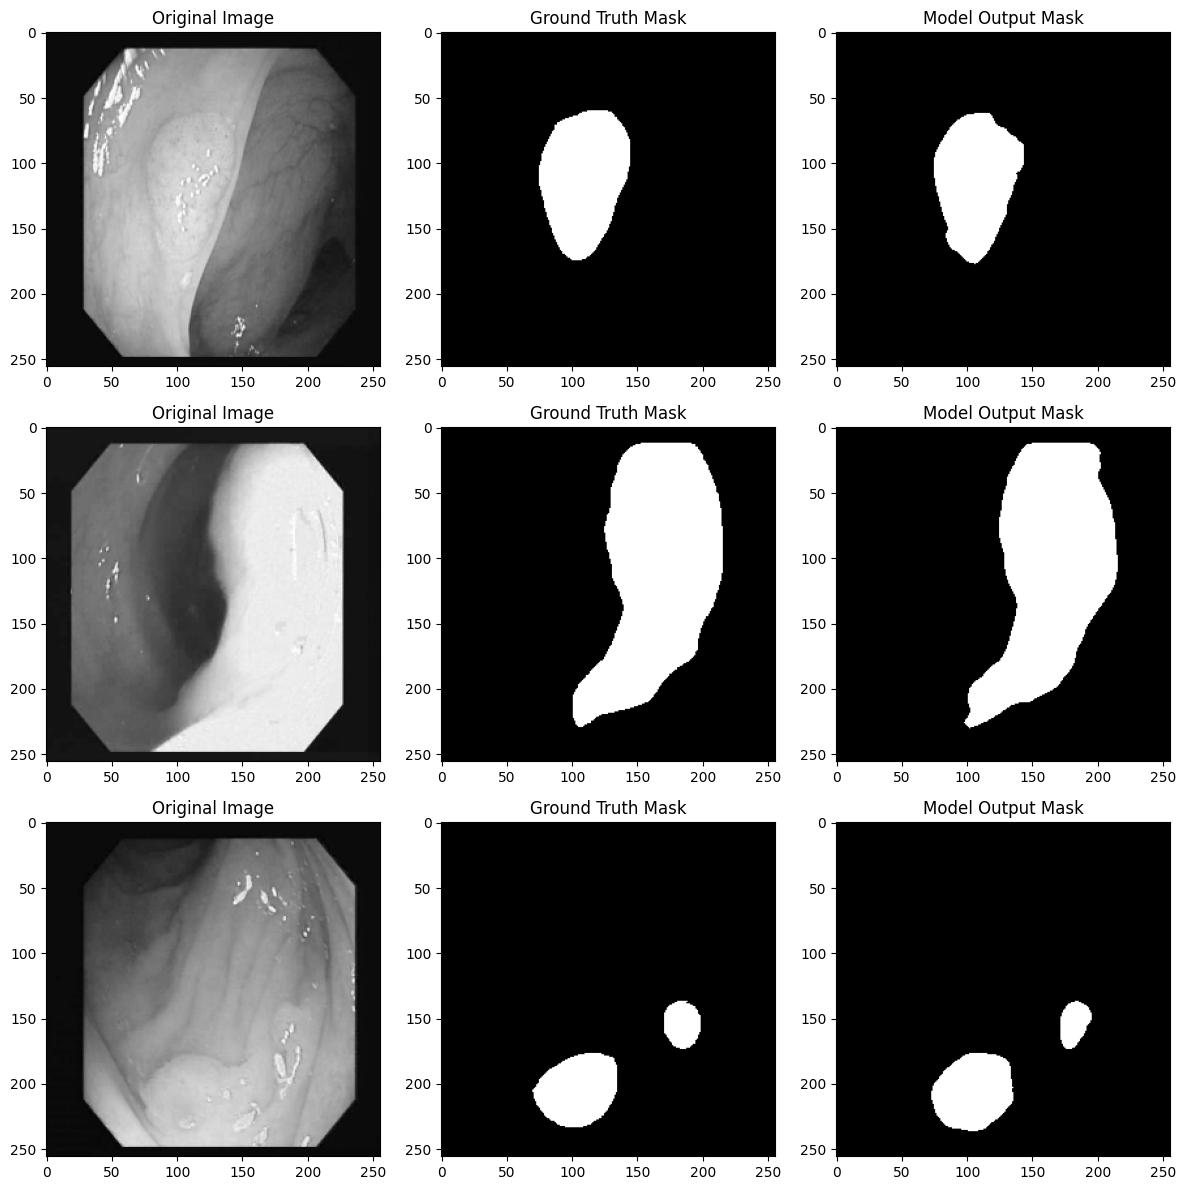

In [8]:
trainer.visualize_output_samples()

In [9]:
trainer.validate_and_save()

100%|██████████| 8/8 [00:00<00:00, 10.07it/s]



MODEL EVALUATION RESULTS
Test Loss                          : 0.4000
Average Dice Score                 : 0.7293
Average Hausdorff Distance         : inf
Average IoU                        : 0.6543
Precision                          : 0.9041
Recall                             : 0.7258
F1 Score                           : 0.8052
IoU (batch avg)                    : 0.6540
Dice (batch avg)                   : 0.7853
Total Parameters                   : 16,158,721
Trainable Parameters               : 16,158,721
Average Inference Time (seconds)   : 0.038884
FPS (Frames Per Second)            : 25.72
FLOPs                              : 26,776,961,024.0
GFLOPs                             : 26.7770

Results saved to: model_comparisons/evaluation_results/ResUNet_model_CVC-ClinicDB_evaluation_results_20250907_180759.csv
Validation results saved to model_comparisons/evaluation_results/ResUNet_model_CVC-ClinicDB_evaluation_results


{'test_loss': 0.4000128097832203,
 'avg_dice_score': 0.7293091763977019,
 'avg_hd_score': inf,
 'avg_iou': 0.6543394100215824,
 'precision': 0.9040858145792128,
 'recall': 0.7257624781505417,
 'f1': 0.8051688788173087,
 'iou_batch_avg': 0.6539895795285702,
 'dice_batch_avg': 0.7852526530623436,
 'total_params': 16158721,
 'trainable_params': 16158721,
 'avg_inference_time': 0.038884057998657226,
 'fps': 25.71748041406925,
 'flops': 26776961024.0,
 'gflops': 26.776961024}

# **Kvasir-SEG dataset**

In [10]:
import torch
from segmentation_models import *

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("CUDA device found.")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("MPS device found.")
else:
    device = torch.device("cpu")
    print("Using CPU.")


CUDA device found.


Total number of samples: 1000
Number of training samples: 900
Number of testing samples: 100


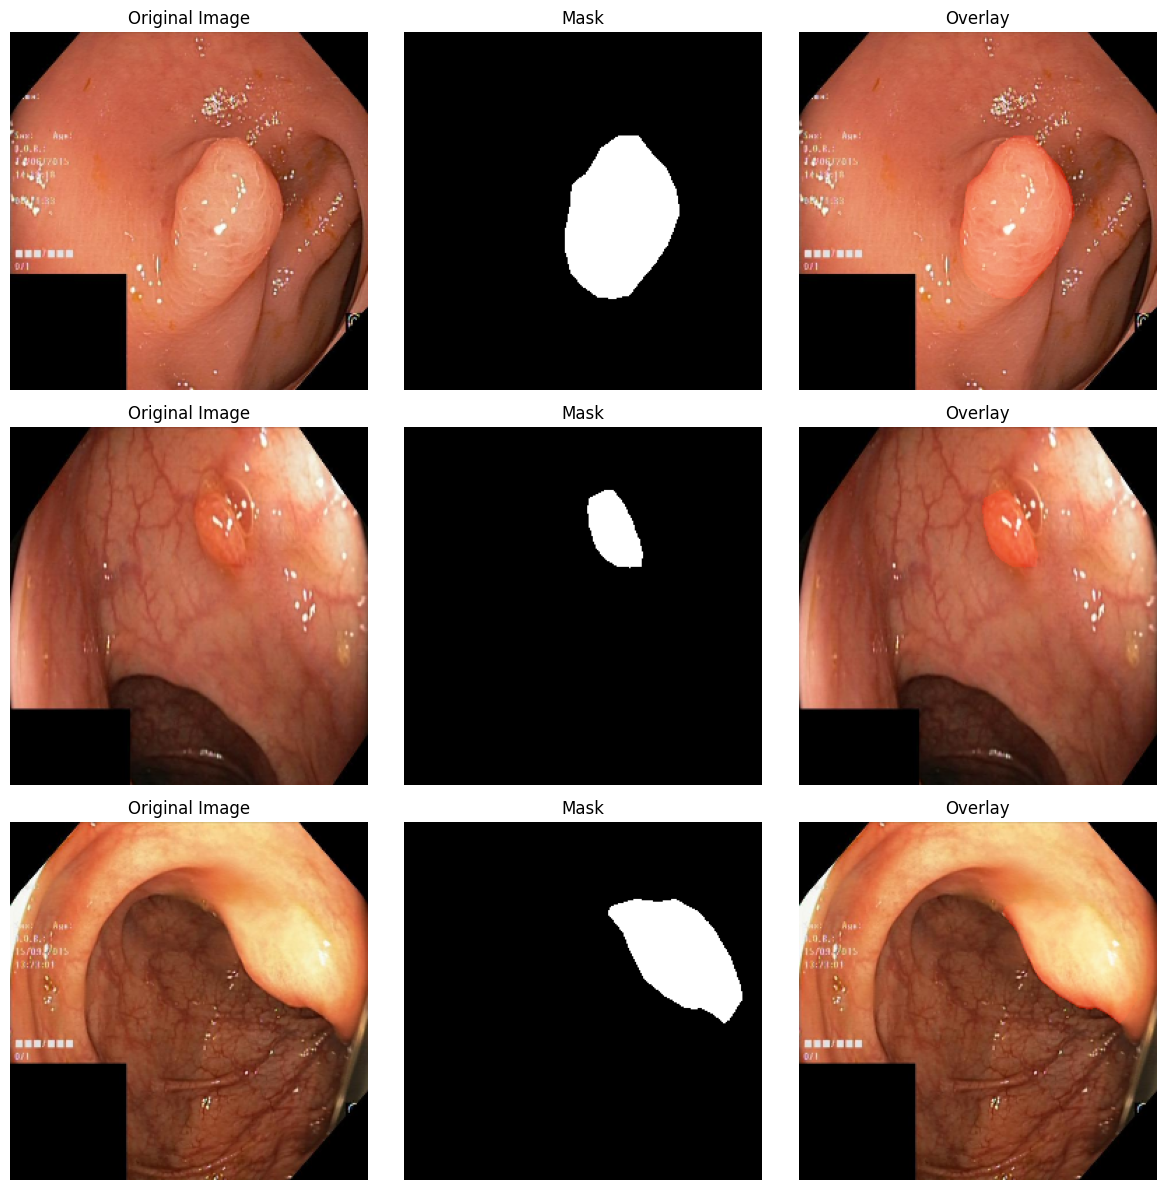

In [11]:
# Dataset Paths
dataset_path = "data/Kvasir-SEG"
image_dir = "images"
mask_dir = "masks"

# Image Preprocessing Parameters
IMG_SIZE = (256, 256)  # Changed to (256, 256) as per the context

dataset = MedicalImageSegmentationData(
    dataset_path=dataset_path,
    image_dir=image_dir,
    mask_dir=mask_dir,
    img_size=IMG_SIZE,
    batch_size=8,
    test_size=0.1,
    random_state=42,
    binarize_mask=True,
)

train_loader, test_loader = dataset.dataloaders()

print(f"Total number of samples: {len(dataset)}")
print(f"Number of training samples: {len(train_loader.dataset)}")
print(f"Number of testing samples: {len(test_loader.dataset)}")

dataset.visualize_samples()

# UNet Kvasir training config

In [12]:
cfg = TrainConfig(
    # --- General ---
    model_name = "ResUNet",
    dataset_name = "Kvasir-SEG",
    criterion = "BCEDiceLoss",
    optimizer = "AdamW",
    epochs = 100,
    lr = 1e-3,
    weight_decay = 1e-4,

    # --- Scheduler ---
    scheduler = "ReduceLROnPlateau",
    scheduler_factor = 0.5,          # for ReduceLROnPlateau
    scheduler_patience = 5,            # for ReduceLROnPlateau
    mode = "min",

    # --- Training control ---
    early_stopping_patience = 10,

    # --- Paths / logging ---
    base_dir="model_comparisons",
    models_dir = "trained_models",
    history_dir = "models_history",
    loss_dir = "loss_plots",
    visualize_dir = "visualizations",
    logs_dir = "logs",
    use_wandb = True,
    wandb_project = "segmentation_models",
    wandb_run_name = None,
    wandb_watch_log_freq = 100,

    # --- Metrics ---
    threshold = 0.5,
    log_train_metrics = True
)

In [13]:
if cfg.use_wandb:
    from dotenv import load_dotenv
    load_dotenv()
    import wandb
    wandb.login(key=os.getenv("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /home/humblebee/.netrc


In [14]:
model = resunet_small(in_channels=3, num_classes=1)
trainer = SegmentationTrainer(model, device, train_loader, test_loader, test_loader, cfg=cfg)
result = trainer.train()
result


2025-09-07 18:16:21 | INFO | ResUNet_model_Kvasir_SEG_20250907_181621 | Logging to model_comparisons/logs/ResUNet_model_Kvasir_SEG_20250907_181621.log


2025-09-07 18:16:21 | INFO | ResUNet_model_Kvasir_SEG_20250907_181621 | W&B URL: https://wandb.ai/iv-drip-counter/segmentation_models/runs/8sncamsp
100%|██████████| 13/13 [00:01<00:00, 11.31it/s]
2025-09-07 18:16:41 | INFO | ResUNet_model_Kvasir_SEG_20250907_181621 | Epoch 001/100 | Train: 1.089720 | Val: 1.012006 | LR: 0.001000 | 20.06s | Val Dice: 0.2770 IoU: 0.1832 F1: 0.3208
2025-09-07 18:16:41 | INFO | ResUNet_model_Kvasir_SEG_20250907_181621 | Saved best: model_comparisons/models/best_ResUNet_model_Kvasir_SEG_20250907_181621.pth (val=1.012006)
100%|██████████| 13/13 [00:01<00:00,  9.07it/s]
2025-09-07 18:17:02 | INFO | ResUNet_model_Kvasir_SEG_20250907_181621 | Epoch 002/100 | Train: 0.957558 | Val: 1.143706 | LR: 0.001000 | 19.83s | Val Dice: 0.2314 IoU: 0.1480 F1: 0.2670
2025-09-07 18:17:02 | INFO | ResUNet_model_Kvasir_SEG_20250907_181621 | No improvement. ES 1/10
100%|██████████| 13/13 [00:02<00:00,  4.88it/s]
2025-09-07 18:17:23 | INFO | ResUNet_model_Kvasir_SEG_20250907_181

avg_flops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_fps,▅▄▆▂▅▆▆█▆█▆▆█▇▇▆▅▇▇▄▆█▃▂▅▅▁▄▆▄▃▆▂▂▅▄▅
avg_gflops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_inference_time,▄▅▃▇▄▃▃▁▃▁▃▃▁▂▂▃▄▂▂▅▃▁▆▇▄▄█▅▃▅▆▃▇▇▄▅▄
epoch_seconds,▂▂▅▆▃▄█▄▃▂▄▄▂▂▂▁▁▃▄▂▃▂▂▃▄▅▃▃▆▄▄▄▃▄▄▄▄
lr,████████████████████████████████▁▁▁▁▁
num_trainable,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/dice,▁▂▂▃▃▄▄▄▄▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇█▇███▇██████
train/f1,▁▂▂▃▃▄▄▄▄▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇█▇███▇██████
train/iou,▁▂▂▂▂▃▃▃▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇█▇█▇▇█████
+11,...


{'best_val_loss': 0.4210778898917712,
 'epochs_ran': 37,
 'best_model_path': 'model_comparisons/models/best_ResUNet_model_Kvasir_SEG_20250907_181621.pth',
 'loss_csv_path': 'model_comparisons/history/loss_history_ResUNet_Kvasir_SEG_20250907_181621.csv',
 'wandb_url': 'https://wandb.ai/iv-drip-counter/segmentation_models/runs/8sncamsp',
 'log_path': 'model_comparisons/logs/ResUNet_model_Kvasir_SEG_20250907_181621.log'}

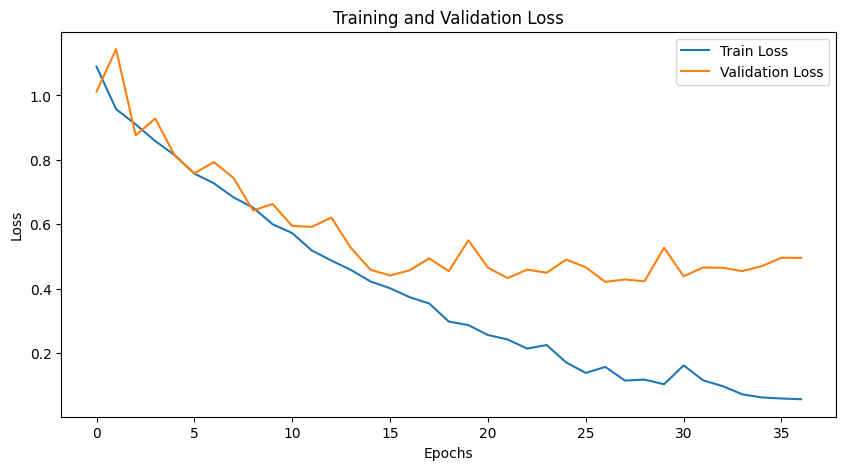

In [15]:
trainer.plot_losses()

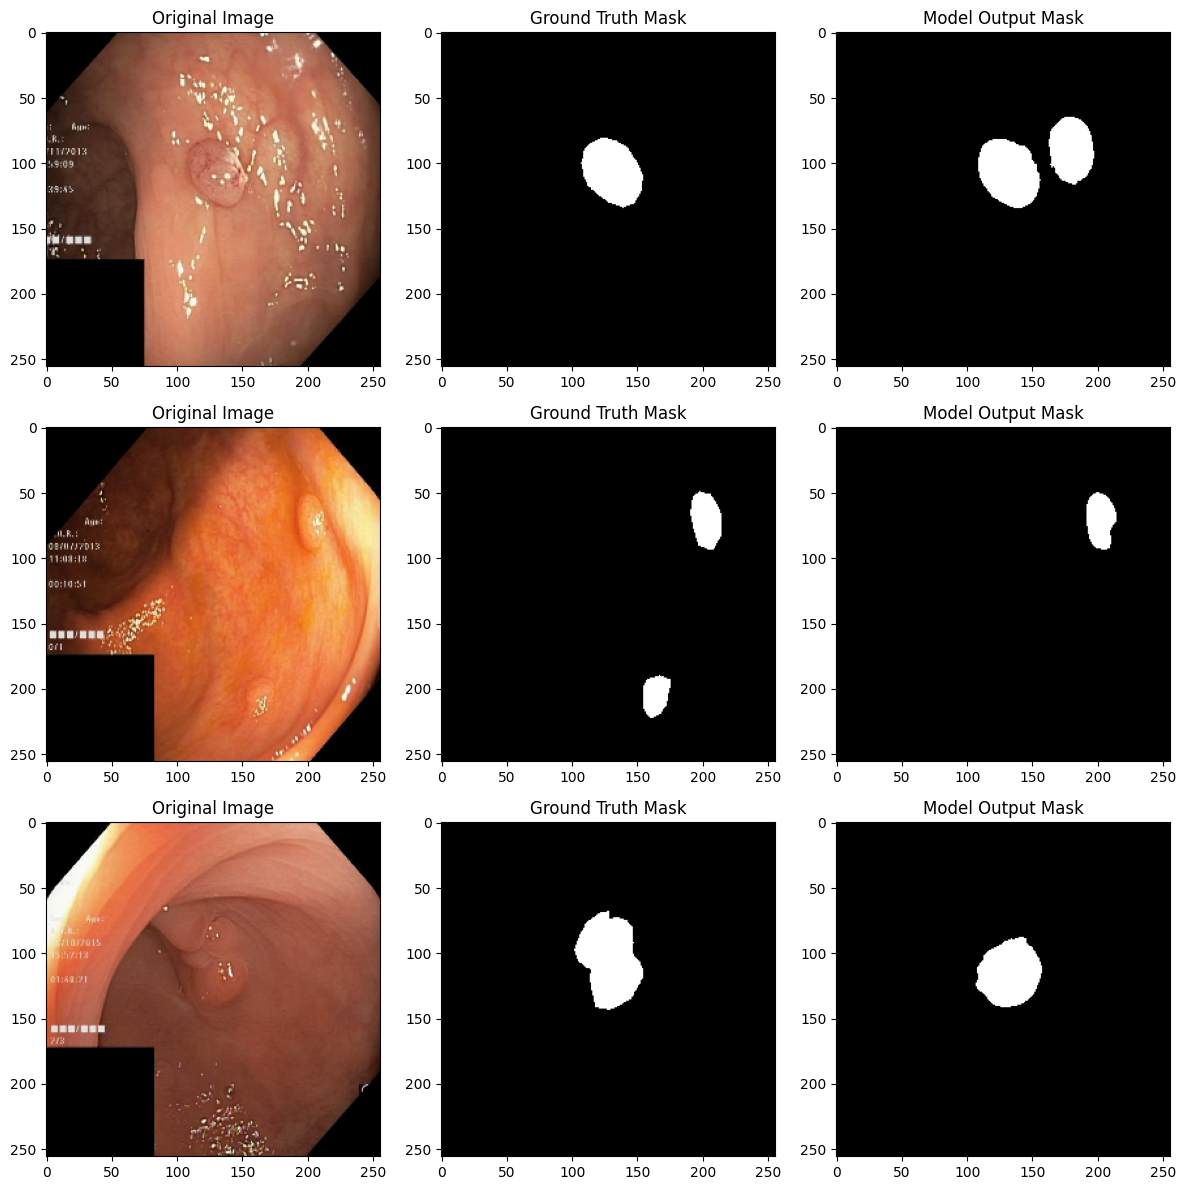

In [16]:
trainer.visualize_output_samples()

In [17]:
trainer.validate_and_save()

100%|██████████| 13/13 [00:02<00:00,  5.05it/s]



MODEL EVALUATION RESULTS
Test Loss                          : 0.4955
Average Dice Score                 : 0.8009
Average Hausdorff Distance         : inf
Average IoU                        : 0.7184
Precision                          : 0.8600
Recall                             : 0.7628
F1 Score                           : 0.8085
IoU (batch avg)                    : 0.6927
Dice (batch avg)                   : 0.8134
Total Parameters                   : 16,158,721
Trainable Parameters               : 16,158,721
Average Inference Time (seconds)   : 0.039086
FPS (Frames Per Second)            : 25.58
FLOPs                              : 26,776,961,024.0
GFLOPs                             : 26.7770

Results saved to: model_comparisons/evaluation_results/ResUNet_model_Kvasir-SEG_evaluation_results_20250907_181621.csv
Validation results saved to model_comparisons/evaluation_results/ResUNet_model_Kvasir-SEG_evaluation_results


{'test_loss': 0.49549830303742337,
 'avg_dice_score': 0.8008546268767706,
 'avg_hd_score': inf,
 'avg_iou': 0.7183512025619885,
 'precision': 0.859957753061882,
 'recall': 0.762808843699654,
 'f1': 0.8084753291727792,
 'iou_batch_avg': 0.6927404082738436,
 'dice_batch_avg': 0.8134484382776114,
 'total_params': 16158721,
 'trainable_params': 16158721,
 'avg_inference_time': 0.03908577442169189,
 'fps': 25.58475595778443,
 'flops': 26776961024.0,
 'gflops': 26.776961024}